Proje: Çalışan İşten Ayrılma Tahmini / Employee Attrition Prediction
Proje Hedefi: Hangi çalışanların işten ayrılma riski yüksek ve şirket hangi çalışanlarına öncelikli müdahale etmeli? 

1.1. Problem Tanımı
Bu projenin amacı, çalışanların işten ayrılma durumlarıyla ilişkili özellikleri analiz ederek işten ayrılma riski taşıyan çalışanları tahmin edebilen bir makine öğrenmesi modeli geliştirmektir.
Çalışanların işten ayrılması, şirketler açısından işe alım, eğitim ve personel kaybı maliyetlerine neden olabilir. Bu nedenle çalışanların iş tatmini, aylık gelir, yaş, fazla mesai durumu ve şirkette çalışma süresi gibi özelliklerinin incelenmesi önemlidir.
Projenin temel iş hedefi, işten ayrılma riski taşıyan çalışanların önceden belirlenmesine yardımcı olarak şirketlerin çalışan bağlılığını artırmaya ve personel kaybını azaltmaya yönelik önlemler almasını desteklemektir.
Modelin tahminleri kesin sonuçlar olarak değil, karar verme sürecini destekleyen tahminler olarak değerlendirilmelidir.

In [2]:
import numpy as np
import pandas as pd

In [4]:
df = pd.read_csv("employee-attrition.csv")

In [6]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [7]:
df.shape

(1470, 35)

1.2. Veri Toplama
Projede IBM HR Employee Attrition veri seti kullanılmıştır. Veri seti, çalışanların kişisel özellikleri, iş koşulları, memnuniyet düzeyleri ve işten ayrılma durumlarıyla ilgili bilgiler içermektedir.
Veri seti Python ortamına aktarılmış ve Pandas kütüphanesi kullanılarak incelenmiştir.
•	Veri satırı sayısı: 1.470
•	Başlangıçtaki sütun sayısı: 35
•	Hedef değişken: Attrition
•	Problem türü: İkili sınıflandırma (Binary Classification)
Attrition değişkeni, çalışanın işten ayrılıp ayrılmadığını ifade etmektedir. Modelin amacı, diğer değişkenlerden yararlanarak bu hedef değişkeni tahmin etmektir.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   str  
 2   BusinessTravel            1470 non-null   str  
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   str  
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   str  
 8   EmployeeCount             1470 non-null   int64
 9   EmployeeNumber            1470 non-null   int64
 10  EnvironmentSatisfaction   1470 non-null   int64
 11  Gender                    1470 non-null   str  
 12  HourlyRate                1470 non-null   int64
 13  JobInvolvement            1470 non-null   int64
 14  JobLevel                  1470 non-null   int64
 15

2.1. Eksik Değerlerin Kontrolü

Veri setindeki eksik değerler Pandas kütüphanesi kullanılarak df.info() komutu ile kontrol edilmiştir. Veri setinin 1470 satır ve 35 sütundan oluştuğu görülmüştür. Çıktıda tüm sütunların 1470 adet dolu (Non-Null) değere sahip olduğu tespit edilmiştir. Bu sonuç, veri setinde eksik değer bulunmadığını göstermektedir. Bu nedenle eksik değerler için herhangi bir doldurma veya silme işlemi uygulanmamıştır.

Ayrıca, Attrition hedef değişkeninin dağılımı df["Attrition"].value_counts() komutu ile incelenmiştir. Sonuçlara göre 1233 çalışanın işten ayrılmadığı (No), 237 çalışanın ise işten ayrıldığı (Yes) görülmüştür.

In [9]:
df["Attrition"].value_counts()

Attrition
No     1233
Yes     237
Name: count, dtype: int64

In [ ]:
pd.crosstab(df["OverTime"], df["Attrition"], normalize="index") * 100 #fazla mesai yapmayanlar 100 çalışandan yaklaşık 90 kişi kalıyor 10 kişi ayrılıyor fazla mesai yapanlar 100 çalışandan yaklaşık 69 kalıyor 31 ayrılıyor

Attrition,No,Yes
OverTime,,
No,89.563567,10.436433
Yes,69.471154,30.528846


Fazla Mesai ve İşten Ayrılma İlişkisi

Çalışanların fazla mesai yapma durumları ile işten ayrılma oranları arasındaki ilişki, pd.crosstab() fonksiyonu kullanılarak incelenmiştir. Analiz sonuçlarına göre fazla mesai yapmayan çalışanların yaklaşık %10,44'ü işten ayrılırken, fazla mesai yapan çalışanlarda bu oran %30,53 olarak hesaplanmıştır.

Bu bulgu, fazla mesai yapan çalışanlarda işten ayrılma oranının daha yüksek olduğunu göstermektedir. Fazla mesai, çalışanların iş yükü ve iş-yaşam dengesi açısından değerlendirilmesi gereken bir faktör olabilir. Ancak bu analiz tek başına fazla mesainin işten ayrılmaya doğrudan neden olduğunu kanıtlamaz.

In [11]:
pd.crosstab(df["JobSatisfaction"], df["Attrition"], normalize="index") * 100  #İş memnuniyeti düşük olan çalışanlar daha fazla mı ayrılıyor?

Attrition,No,Yes
JobSatisfaction,,
1,77.162630,22.837370
2,83.571429,16.428571
3,83.484163,16.515837
4,88.671024,11.328976


İş Memnuniyeti ve İşten Ayrılma İlişkisi

Çalışanların iş memnuniyeti düzeyleri ile işten ayrılma oranları arasındaki ilişki incelenmiştir. Bu analizde 1 en düşük, 4 ise en yüksek iş memnuniyeti düzeyini ifade etmektedir.

Sonuçlara göre iş memnuniyeti düzeyi 1 olan çalışanlarda işten ayrılma oranı %22,84 iken, düzeyi 4 olan çalışanlarda bu oran %11,33'tür. Memnuniyet düzeyi 2 olan çalışanlarda ayrılma oranı %16,43, düzeyi 3 olan çalışanlarda ise %16,52 olarak hesaplanmıştır.

Genel olarak, iş memnuniyeti en düşük olan çalışanların işten ayrılma oranının en yüksek memnuniyet düzeyindeki çalışanlara kıyasla daha fazla olduğu görülmüştür. Bu bulgu, iş memnuniyetinin çalışanların işte kalma durumuyla ilişkili olabileceğini göstermektedir.

In [12]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

Veri setindeki eksik değerler Pandas kütüphanesinin df.isnull().sum() komutu ile kontrol edilmiştir. Sonuçlarda tüm sütunlar için eksik değer sayısının 0 olduğu görülmüştür. Bu nedenle eksik değerleri doldurma veya eksik kayıtları silme işlemine gerek duyulmamıştır.

In [13]:
df.nunique().sort_values()

EmployeeCount                  1
Over18                         1
StandardHours                  1
Attrition                      2
OverTime                       2
PerformanceRating              2
Gender                         2
BusinessTravel                 3
Department                     3
MaritalStatus                  3
RelationshipSatisfaction       4
StockOptionLevel               4
JobSatisfaction                4
EnvironmentSatisfaction        4
JobInvolvement                 4
WorkLifeBalance                4
Education                      5
JobLevel                       5
EducationField                 6
TrainingTimesLastYear          7
JobRole                        9
NumCompaniesWorked            10
PercentSalaryHike             15
YearsSinceLastPromotion       16
YearsWithCurrManager          18
YearsInCurrentRole            19
DistanceFromHome              29
YearsAtCompany                37
TotalWorkingYears             40
Age                           43
HourlyRate

Değişkenlerin Benzersiz Değer Sayılarının İncelenmesi

Veri setindeki değişkenlerin çeşitliliğini ve yapısını anlamak amacıyla df.nunique().sort_values() komutu kullanılarak her sütundaki benzersiz değer sayıları incelenmiştir.

İnceleme sonucunda, EmployeeCount, Over18 ve StandardHours değişkenlerinin yalnızca bir benzersiz değer içerdiği görülmüştür. Bu değişkenler veri setinde farklılık göstermediği için çalışanların işten ayrılma durumunu tahmin etme açısından ayırt edici bilgi sağlamamaktadır. Bu nedenle modelleme öncesinde çıkarılmaları değerlendirilebilir.

Attrition hedef değişkeninin iki benzersiz değere sahip olduğu görülmüştür. Bu durum, problemin çalışanların işten ayrılıp ayrılmamasını tahmin etmeye yönelik ikili sınıflandırma problemi olduğunu göstermektedir.

Gender, OverTime ve PerformanceRating gibi değişkenler iki farklı değer içerirken; BusinessTravel, Department ve MaritalStatus gibi kategorik değişkenlerde üç farklı değer bulunmaktadır. JobSatisfaction, EnvironmentSatisfaction ve RelationshipSatisfaction gibi değişkenler ise dört farklı değer içermektedir.

Age, TotalWorkingYears ve YearsAtCompany gibi değişkenlerin farklı sayıda sayısal değer içerdiği görülmüştür. MonthlyIncome, MonthlyRate ve DailyRate gibi değişkenler de geniş bir değer çeşitliliğine sahiptir. EmployeeNumber değişkeninin 1.470 benzersiz değer içermesi, her çalışan için farklı bir numara bulunduğunu göstermektedir; ancak bu sütun doğrudan tahmin edici bir özellik olarak kullanılmak yerine kimlik bilgisi niteliği açısından değerlendirilmelidir.

Sonuç olarak, benzersiz değer sayıları veri setindeki sabit değişkenlerin, kategorik değişkenlerin ve sayısal değişkenlerin belirlenmesine yardımcı olmuştur. Bu inceleme, modelleme öncesinde gereksiz değişkenlerin değerlendirilmesi ve veri setinin daha iyi anlaşılması açısından önemli bir adımdır.

In [14]:
numeric_outlier_cols = [
    "Age",
    "DailyRate",
    "DistanceFromHome",
    "HourlyRate",
    "MonthlyIncome",
    "MonthlyRate",
    "NumCompaniesWorked",
    "PercentSalaryHike",
    "TotalWorkingYears",
    "TrainingTimesLastYear",
    "YearsAtCompany",
    "YearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager"
]

for col in numeric_outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outlier_count = ((df[col] < lower) | (df[col] > upper)).sum()
    
    print(f"{col}: {outlier_count} aykırı değer")

Age: 0 aykırı değer
DailyRate: 0 aykırı değer
DistanceFromHome: 0 aykırı değer
HourlyRate: 0 aykırı değer
MonthlyIncome: 114 aykırı değer
MonthlyRate: 0 aykırı değer
NumCompaniesWorked: 52 aykırı değer
PercentSalaryHike: 0 aykırı değer
TotalWorkingYears: 63 aykırı değer
TrainingTimesLastYear: 238 aykırı değer
YearsAtCompany: 104 aykırı değer
YearsInCurrentRole: 21 aykırı değer
YearsSinceLastPromotion: 107 aykırı değer
YearsWithCurrManager: 14 aykırı değer


Aykırı Değerlerin İncelenmesi
Sayısal değişkenlerde aykırı değerler incelenmiştir. Aykırı değerler, bir değişkendeki diğer gözlemlere göre olağandışı derecede yüksek veya düşük değerlere sahip gözlemlerdir.
İnceleme sonucunda bazı değişkenlerde aykırı değerler tespit edilmiştir. Örnekler:
•	MonthlyIncome: 114 aykırı değer
•	NumCompaniesWorked: 52 aykırı değer
•	TotalWorkingYears: 63 aykırı değer
•	TrainingTimesLastYear: 238 aykırı değer
•	YearsAtCompany: 104 aykırı değer
•	YearsSinceLastPromotion: 107 aykırı değer
Bu değerler, veri setinin özelliklerini daha iyi anlamak amacıyla incelenmiştir. Bir değerin aykırı olması tek başına hatalı olduğu anlamına gelmediğinden, çalışanlara ait gerçekçi gözlemlerin doğrudan silinmesi uygun görülmemiştir.

In [15]:
df = df.drop(columns=[
    "EmployeeNumber",
    "EmployeeCount",
    "Over18",
    "StandardHours"
])

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


Gereksiz Değişkenlerin Veri Setinden Çıkarılması

Veri hazırlama aşamasında, modelleme sürecine katkı sağlamadığı değerlendirilen EmployeeNumber, EmployeeCount, Over18 ve StandardHours sütunları veri setinden çıkarılmıştır. Bu işlem Pandas kütüphanesinin drop() fonksiyonu kullanılarak gerçekleştirilmiştir.

Bu değişkenlerin çıkarılmasıyla veri setindeki sütun sayısı 35'ten 31'e düşürülmüştür. İşlem sonrasında head() fonksiyonu kullanılarak veri setinin ilk beş satırı kontrol edilmiş ve kalan değişkenlerin veri yapısı incelenmiştir.

Bu düzenleme ile modelleme öncesinde gereksiz bilgilerin azaltılması ve veri setinin daha uygun bir yapıya getirilmesi amaçlanmıştır.

In [16]:
categorical_features = df.select_dtypes(include=["object"]).columns

print(categorical_features)

Index(['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender',
       'JobRole', 'MaritalStatus', 'OverTime'],
      dtype='str')


C:\Users\adelikan\AppData\Local\Temp\ipykernel_13880\1098135602.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=["object"]).columns


Kategorik Değişkenlerin Belirlenmesi

Veri setindeki kategorik değişkenleri belirlemek amacıyla Pandas kütüphanesinin select_dtypes() fonksiyonu kullanılmıştır. İnceleme sonucunda sekiz kategorik sütun tespit edilmiştir: Attrition, BusinessTravel, Department, EducationField, Gender, JobRole, MaritalStatus ve OverTime.

Bu değişkenler çalışanların işten ayrılma durumunu, seyahat sıklığını, çalıştıkları departmanı, eğitim alanlarını, cinsiyetlerini, iş rollerini, medeni durumlarını ve fazla mesai durumlarını temsil etmektedir.

Attrition değişkeni, çalışanın işten ayrılıp ayrılmadığını belirten hedef değişkendir. Diğer kategorik değişkenler ise modelin tahmin sürecinde kullanılabilecek özelliklerdir.

Makine öğrenmesi algoritmalarının kategorik verileri doğrudan işleyemediği durumlarda bu değişkenlerin sayısal biçime dönüştürülmesi gerekir. Bu proje kapsamında kategorik değişkenlerin modele uygun hâle getirilmesi için One-Hot Encoding yöntemi kullanılmıştır.

In [17]:
df["Attrition"] = df["Attrition"].map({
    "No": 0,
    "Yes": 1
})

df["Attrition"].head()

0    1
1    0
2    1
3    0
4    0
Name: Attrition, dtype: int64

Hedef Değişkenin Sayısal Olarak Kodlanması

Makine öğrenmesi modelinde kullanılacak hedef değişken olan Attrition, başlangıçta kategorik değerlerden oluşmaktadır. Modelin bu değişkeni işleyebilmesi için kategorik değerler sayısal biçime dönüştürülmüştür.

Bu amaçla map() fonksiyonu kullanılarak çalışanların işten ayrılma durumları aşağıdaki şekilde kodlanmıştır:

No → 0: Çalışan işten ayrılmamıştır.

Yes → 1: Çalışan işten ayrılmıştır.

İşlem sonrasında değişkenin veri tipi int64 olarak görülmüştür. Bu sonuç, hedef değişkenin tam sayı biçiminde kodlandığını göstermektedir.

Bu dönüşüm sayesinde Attrition değişkeni ikili sınıflandırma probleminde hedef değişken olarak kullanılmaya hazır hâle getirilmiştir.

In [18]:
categorical_features = [
    "BusinessTravel",
    "Department",
    "EducationField",
    "Gender",
    "JobRole",
    "MaritalStatus",
    "OverTime"
]

print(categorical_features)

['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']


In [19]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    drop="first",
    sparse_output=False
)

encoded_data = encoder.fit_transform(df[categorical_features])

print(encoded_data.shape)

(1470, 21)


Veri setindeki kategorik özelliklerden BusinessTravel, Department, EducationField, Gender, JobRole, MaritalStatus ve OverTime olmak üzere yedi değişken One-Hot Encoding yöntemiyle sayısal biçime dönüştürülmüştür. Tahmin edilmesi amaçlanan Attrition hedef değişkeni bu işleme dâhil edilmemiştir.

Dönüşüm sırasında handle_unknown="ignore" parametresi, daha önce görülmeyen kategorilerin işlenmesinde hata oluşmasını önlemek; drop="first" parametresi ise her değişkenin ilk kategorisini çıkararak gereksiz sütun tekrarını azaltmak amacıyla kullanılmıştır.

İşlem sonucunda 1.470 satır ve 21 sütundan oluşan kodlanmış bir veri elde edilmiştir. Böylece kategorik özellikler, makine öğrenmesi modelinde kullanılabilecek sayısal bir gösterime dönüştürülmüştür.

In [22]:
X = df.drop(columns=["Attrition"])
y = df["Attrition"]

In [23]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

numeric_columns = X.select_dtypes(include=["int64", "float64"]).columns

X[numeric_columns] = scaler.fit_transform(X[numeric_columns])

X.head()

,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,0.547619,Travel_Rarely,0.715820,Sales,0.000000,0.25,Life Sciences,0.333333,Female,0.914286,...,0.0,0.000000,0.000000,0.200,0.0,0.000000,0.15,0.222222,0.000000,0.294118
1,0.738095,Travel_Frequently,0.126700,Research & Development,0.250000,0.00,Life Sciences,0.666667,Male,0.442857,...,1.0,1.000000,0.333333,0.250,0.5,0.666667,0.25,0.388889,0.066667,0.411765
2,0.452381,Travel_Rarely,0.909807,Research & Development,0.035714,0.25,Other,1.000000,Male,0.885714,...,0.0,0.333333,0.000000,0.175,0.5,0.666667,0.00,0.000000,0.000000,0.000000
3,0.357143,Travel_Frequently,0.923407,Research & Development,0.071429,0.75,Life Sciences,1.000000,Female,0.371429,...,0.0,0.666667,0.000000,0.200,0.5,0.666667,0.20,0.388889,0.200000,0.000000
4,0.214286,Travel_Rarely,0.350036,Research & Development,0.035714,0.00,Medical,0.000000,Male,0.142857,...,0.0,1.000000,0.333333,0.150,0.5,0.666667,0.05,0.111111,0.133333,0.117647


In [24]:
X.shape

(1470, 30)

Modelleme İçin Özellik Matrisinin Oluşturulması

Veri hazırlama aşamasında hedef değişken olan Attrition, bağımsız değişkenlerden ayrılmış ve modelleme için X özellik matrisi oluşturulmuştur. X.shape çıktısı, veri setinin 1.470 satır ve 30 sütundan oluştuğunu göstermiştir. Buna göre modelleme için 1.470 çalışan kaydı ve 30 bağımsız özellik bulunmaktadır.

Bu aşamada sayısal değişkenlere Min-Max ölçeklendirmesi uygulanarak değerlerin 0 ile 1 aralığına getirilmesi amaçlanmıştır. Hazırlanan özellik matrisi, sonraki aşamada eğitim ve test kümelerinin oluşturulması ve makine öğrenmesi modellerinin eğitilmesi için kullanılacaktır.

In [25]:
X[numeric_columns].describe()

,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.000000,1470.000000,1470.00000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,0.450567,0.501421,0.292590,0.478231,0.573923,0.512731,0.576644,0.265986,0.576190,0.289307,...,0.153741,0.570748,0.264626,0.28199,0.466553,0.587075,0.175204,0.234958,0.145850,0.242537
std,0.217509,0.288840,0.289531,0.256041,0.364361,0.290420,0.237187,0.276735,0.367615,0.247918,...,0.360824,0.360403,0.284026,0.19452,0.214878,0.235492,0.153163,0.201285,0.214829,0.209890
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.285714,0.259843,0.035714,0.250000,0.333333,0.257143,0.333333,0.000000,0.333333,0.100158,...,0.000000,0.333333,0.000000,0.15000,0.333333,0.333333,0.075000,0.111111,0.000000,0.117647
50%,0.428571,0.501074,0.214286,0.500000,0.666667,0.514286,0.666667,0.250000,0.666667,0.205898,...,0.000000,0.666667,0.333333,0.25000,0.500000,0.666667,0.125000,0.166667,0.066667,0.176471
75%,0.595238,0.755190,0.464286,0.750000,1.000000,0.767857,0.666667,0.500000,1.000000,0.388099,...,0.000000,1.000000,0.333333,0.37500,0.500000,0.666667,0.225000,0.388889,0.200000,0.411765
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Sayısal Değişkenlerin İstatistiksel Olarak İncelenmesi

Sayısal değişkenlerin dağılımlarını incelemek amacıyla describe() fonksiyonu kullanılarak gözlem sayısı, ortalama, standart sapma, minimum, çeyreklikler ve maksimum değerler değerlendirilmiştir.

Min-Max ölçeklendirmesi sonrasında sayısal değişkenlerin minimum değerlerinin 0, maksimum değerlerinin ise 1 olduğu görülmüştür. Ortalama ve standart sapma değerleri, değişkenlerin veri setindeki dağılımları hakkında bilgi sağlamaktadır.

İnceleme sonucunda sayısal değişkenlerin ortak bir ölçeğe getirildiği ve sonraki modelleme aşaması için hazırlandığı görülmüştür.

In [26]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 30 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Age                       1470 non-null   float64
 1   BusinessTravel            1470 non-null   str    
 2   DailyRate                 1470 non-null   float64
 3   Department                1470 non-null   str    
 4   DistanceFromHome          1470 non-null   float64
 5   Education                 1470 non-null   float64
 6   EducationField            1470 non-null   str    
 7   EnvironmentSatisfaction   1470 non-null   float64
 8   Gender                    1470 non-null   str    
 9   HourlyRate                1470 non-null   float64
 10  JobInvolvement            1470 non-null   float64
 11  JobLevel                  1470 non-null   float64
 12  JobRole                   1470 non-null   str    
 13  JobSatisfaction           1470 non-null   float64
 14  MaritalStatus      

Veri Setinin Yapısının ve Veri Tiplerinin Kontrolü

Veri hazırlama işlemlerinden sonra X.info() fonksiyonu kullanılarak özellik matrisinin boyutu, sütunların veri tipleri ve eksik olmayan gözlem sayıları kontrol edilmiştir.

İnceleme sonucunda veri setinin 1.470 satır ve 30 sütundan oluştuğu belirlenmiştir. Sütunların 23'ü float64, 7'si ise str veri tipindedir. Tüm sütunlarda 1.470 adet eksik olmayan gözlem bulunması, mevcut özellik matrisinde eksik değer olmadığını göstermektedir.

Bununla birlikte, BusinessTravel, Department, EducationField, Gender, JobRole, MaritalStatus ve OverTime değişkenlerinin hâlâ metinsel kategorik değerler içerdiği görülmüştür. Bu nedenle modelleme öncesinde bu sütunların uygun bir kodlama yöntemiyle sayısal biçime dönüştürülmesi gerekmektedir.

Sonuç olarak, veri setinin boyutu, veri tipleri ve eksik değer durumu kontrol edilmiş; kategorik değişkenlerin modelleme için dönüştürülmesi gereken bir sonraki adım olduğu belirlenmiştir.

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Eğitim veri boyutu:", X_train.shape)
print("Test veri boyutu:", X_test.shape)

Eğitim veri boyutu: (1176, 30)
Test veri boyutu: (294, 30)


Eğitim ve Test Veri Setlerinin Oluşturulması

Makine öğrenmesi modellerinin eğitilmesi ve performanslarının daha önce görülmemiş veriler üzerinde değerlendirilmesi amacıyla veri seti eğitim ve test kümelerine ayrılmıştır. Bu işlem için Scikit-learn kütüphanesinin train_test_split() fonksiyonu kullanılmıştır.

Veri setinin %80'i eğitim, %20'si test amacıyla ayrılmıştır. test_size=0.20 parametresi test kümesinin oranını belirtirken, random_state=42 parametresi işlemin tekrarlanabilir olmasını sağlamaktadır.

Hedef değişken olan Attrition sınıflarının eğitim ve test kümelerinde benzer oranlarda temsil edilmesini sağlamak amacıyla stratify=y parametresi kullanılmıştır.

İşlem sonucunda 1.176 kayıt eğitim kümesine, 294 kayıt test kümesine ayrılmıştır. Böylece modelin eğitim verileri üzerinde öğrenmesi ve performansının ayrı tutulan test verileri üzerinde değerlendirilmesi için gerekli veri ayrımı gerçekleştirilmiştir.

Her iki kümede de 30 özellik bulunuyor. y_train ve y_test ise bu çalışanların ayrılma durumlarını içeriyor. 1176 çalışanın 30 farklı özelliğine, 294 çalışanın 30 farklı özelliğine baktım.

Veri setimde toplam 1.470 çalışan var ve verileri %80 eğitim, %20 test olarak ayırdım.

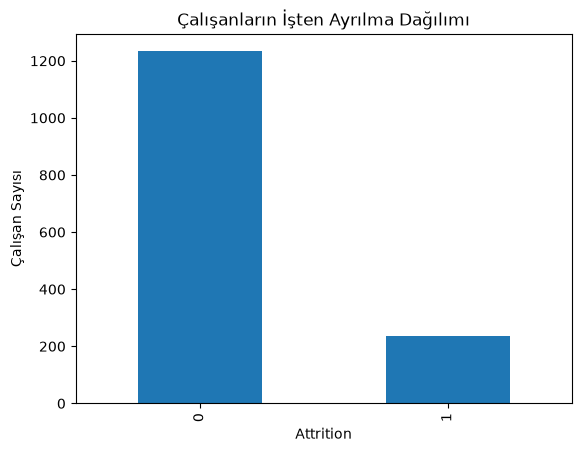

In [28]:
import matplotlib.pyplot as plt

df["Attrition"].value_counts().plot(kind="bar")

plt.title("Çalışanların İşten Ayrılma Dağılımı")
plt.xlabel("Attrition")
plt.ylabel("Çalışan Sayısı")
plt.show()

Çalışanların İşten Ayrılma Dağılımının İncelenmesi

Çalışanların işten ayrılma durumlarını incelemek amacıyla Attrition değişkeninin dağılımı sütun grafiği ile görselleştirilmiştir. Veri setinde 0, işten ayrılmayan çalışanları; 1 ise işten ayrılan çalışanları temsil etmektedir.

Grafik incelendiğinde, işten ayrılmayan çalışanların sayısının yaklaşık 1.200, işten ayrılan çalışanların sayısının ise yaklaşık 200 olduğu görülmektedir. Bu durum, veri setinde işten ayrılmayan çalışanların çoğunlukta olduğunu ve iki sınıf arasında belirgin bir dengesizlik bulunduğunu göstermektedir.

Bu dengesizlik, makine öğrenmesi modelinin çalışanların işten ayrılma durumunu tahmin etmesini etkileyebilir. Bu nedenle model değerlendirilirken yalnızca doğruluk (Accuracy) metriğine değil, özellikle işten ayrılan çalışanları ne ölçüde doğru belirlediğini gösteren Recall ve F1-score metriklerine de dikkat edilmelidir.

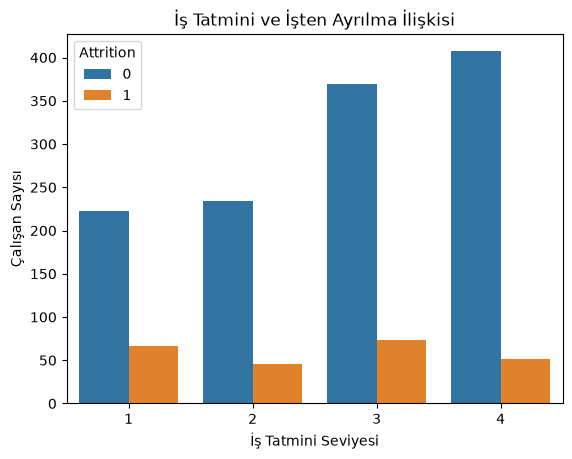

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x="JobSatisfaction", hue="Attrition")

plt.title("İş Tatmini ve İşten Ayrılma İlişkisi")
plt.xlabel("İş Tatmini Seviyesi")
plt.ylabel("Çalışan Sayısı")
plt.show()

İş tatmini ile çalışanların işten ayrılması arasında belirgin bir ilişki gözlemlenmiştir. 
İş tatmini seviyesi 1 olan çalışanlarda işten ayrılma oranı %22,84 iken, tatmin seviyesi 4 olan çalışanlarda bu oran %11,33'e düşmektedir. 
Bu bulgu, düşük iş tatmininin çalışan ayrılma riskini artırabileceğini göstermektedir.

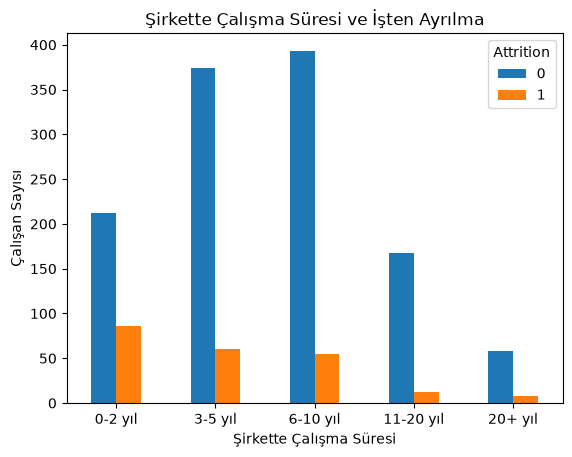

In [30]:
df["YearsAtCompanyGroup"] = pd.cut(
    df["YearsAtCompany"],
    bins=[0, 2, 5, 10, 20, 50],
    labels=["0-2 yıl", "3-5 yıl", "6-10 yıl", "11-20 yıl", "20+ yıl"]
)

grafik = pd.crosstab(
    df["YearsAtCompanyGroup"],
    df["Attrition"]
)

grafik.plot(kind="bar")

plt.title("Şirkette Çalışma Süresi ve İşten Ayrılma")
plt.xlabel("Şirkette Çalışma Süresi")
plt.ylabel("Çalışan Sayısı")
plt.xticks(rotation=0)
plt.show()

Şirkette Çalışma Süresi ile İşten Ayrılma İlişkisinin İncelenmesi

Çalışanların şirkette geçirdikleri süre ile işten ayrılma durumları arasındaki ilişkiyi incelemek amacıyla YearsAtCompany değişkeni belirli aralıklara ayrılmıştır. Çalışma süreleri 0–2 yıl, 3–5 yıl, 6–10 yıl, 11–20 yıl ve 20 yıl üzeri olmak üzere beş grupta incelenmiştir. Her gruptaki işten ayrılan ve ayrılmayan çalışan sayıları sütun grafiği ile görselleştirilmiştir.

Grafik incelendiğinde, 3–5 yıl ve 6–10 yıl aralığında şirkette çalışanların sayısının diğer gruplara göre daha yüksek olduğu görülmektedir. İşten ayrılan çalışanların sayısı ise özellikle 0–2 yıl grubunda dikkat çekmektedir. Bu bulgu, çalışanların şirketteki ilk yıllarında işten ayrılma durumunun incelenmesinin önemli olduğunu düşündürmektedir.

Bununla birlikte, grafikte çalışanların sayısal dağılımı gösterilmektedir. Gruplardaki toplam çalışan sayıları farklı olduğundan, hangi çalışma süresi grubunda işten ayrılma olasılığının daha yüksek olduğunu kesin olarak belirlemek için her grubun işten ayrılma yüzdesinin ayrıca hesaplanması gerekir.

Bu analiz, şirkette çalışma süresinin çalışanların işten ayrılma davranışıyla ilişkili olabileceğini göstermekte ve çalışan bağlılığını artırmaya yönelik uygulamalar geliştirilmesi açısından önemli bir başlangıç sunmaktadır.

In [31]:
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 100],
    labels=["18-25", "26-35", "36-45", "46+"]
)

df[["Age", "AgeGroup"]].head()

,Age,AgeGroup
0,41,36-45
1,49,46+
2,37,36-45
3,33,26-35
4,27,26-35


Yaş Gruplarına Göre Sınıflandırma

Çalışanların yaşlarını daha kolay analiz edebilmek amacıyla Age değişkeninden yararlanılarak AgeGroup adlı yeni bir değişken oluşturulmuştur. Çalışanlar 18–25, 26–35, 36–45 ve 46 yaş ve üzeri olmak üzere dört gruba ayrılmıştır.

Kodun çıktısında ilk beş çalışanın yaşları ve ait oldukları yaş grupları görüntülenmiştir. Örneğin, 41 yaşındaki çalışan 36–45 grubuna, 49 yaşındaki çalışan 46+ grubuna, 33 ve 27 yaşındaki çalışanlar ise 26–35 grubuna atanmıştır.

Bu işlem sonucunda yaş bilgileri kategorik gruplara dönüştürülerek yaş grupları arasındaki farklılıkların incelenmesi kolaylaştırılmıştır. Oluşturulan değişken, sonraki analizlerde yaş grupları ile çalışanların işten ayrılma durumları arasındaki ilişkinin değerlendirilmesinde kullanılacaktır.

In [32]:
df["AgeGroup"].value_counts().sort_index()

AgeGroup
18-25    123
26-35    606
36-45    468
46+      273
Name: count, dtype: int64

Yaş Gruplarına Göre Çalışan Dağılımı

Çalışanların yaş gruplarına göre dağılımını incelemek amacıyla AgeGroup değişkeninin frekans analizi yapılmıştır. Analiz sonucunda 1.470 çalışanın yaş gruplarına dağılımı şu şekilde belirlenmiştir:

18–25 yaş: 123 çalışan

26–35 yaş: 606 çalışan

36–45 yaş: 468 çalışan

46 yaş ve üzeri: 273 çalışan

Sonuçlara göre, veri setinde en fazla çalışan 26–35 yaş grubunda, en az çalışan ise 18–25 yaş grubundadır. Bu bulgu, incelenen veri setindeki çalışanların ağırlıklı olarak 26–45 yaş aralığında bulunduğunu göstermektedir.

Bu sınıflandırma, yaş gruplarının çalışanların işten ayrılma durumlarıyla ilişkisini daha ayrıntılı incelemek için temel oluşturmaktadır. Ancak bu sonuçlar yalnızca çalışanların yaş dağılımını göstermekte, yaş gruplarına göre işten ayrılma oranlarını tek başına açıklamamaktadır.

In [33]:
age_attrition = pd.crosstab(
    df["AgeGroup"],
    df["Attrition"],
    normalize="index"
) * 100

age_attrition

Attrition,0,1
AgeGroup,,
18-25,64.227642,35.772358
26-35,80.858086,19.141914
36-45,90.811966,9.188034
46+,87.545788,12.454212


Yaş Grupları ile İşten Ayrılma Oranı Arasındaki İlişkinin İncelenmesi

Çalışanların yaş gruplarına göre işten ayrılma oranlarını incelemek amacıyla pd.crosstab() fonksiyonu kullanılmış ve normalize="index" parametresi ile her yaş grubunun kendi içerisindeki yüzdesel dağılımı hesaplanmıştır. Analizde Attrition = 0 işten ayrılmayan çalışanları, Attrition = 1 ise işten ayrılan çalışanları temsil etmektedir.

Analiz sonuçlarına göre:

18–25 yaş grubunda çalışanların %35,77'si işten ayrılmış, %64,23'ü şirkette kalmıştır.

26–35 yaş grubunda çalışanların %19,14'ü işten ayrılmış, %80,86'sı şirkette kalmıştır.

36–45 yaş grubunda çalışanların %9,19'u işten ayrılmış, %90,81'i şirkette kalmıştır.

46 yaş ve üzeri grupta çalışanların %12,45'i işten ayrılmış, %87,55'i şirkette kalmıştır.

Sonuçlar, işten ayrılma oranının en yüksek olduğu grubun 18–25 yaş aralığındaki çalışanlar olduğunu göstermektedir. En düşük işten ayrılma oranı ise 36–45 yaş grubunda görülmektedir. Ayrıca 46 yaş ve üzerindeki çalışanların işten ayrılma oranı, 36–45 yaş grubuna kıyasla bir miktar daha yüksektir.

Bu bulgular, veri setinde genç çalışanların işten ayrılma eğiliminin daha yüksek olduğunu ve yaş değişkeninin çalışanların işten ayrılma durumunu analiz ederken dikkate alınabilecek bir özellik olduğunu göstermektedir. Bununla birlikte, bu sonuçlar tek başına yaşın işten ayrılmanın nedeni olduğunu kanıtlamaz; başka çalışma koşulları ve değişkenler de bu durumu etkileyebilir.

18–25 yaş grubunda işten ayrılma oranı yaklaşık %35,8, 36–45 yaş grubunda ise yaklaşık %9,2. Yani bu veri setinde genç çalışanların işten ayrılma oranı belirgin biçimde daha yüksek görünüyor.

In [34]:
X_train.shape
# (1176, 30)

X_test.shape
# (294, 30)

(294, 30)

Eğitim ve Test Veri Kümelerinin Oluşturulması

Makine öğrenmesi modelinin eğitilmesi ve performansının değerlendirilmesi amacıyla veri seti eğitim ve test kümelerine ayrılmıştır. Veri setindeki toplam 1.470 çalışanın %80'i eğitim, %20'si test için kullanılmıştır.

Eğitim kümesi (X_train): 1.176 çalışan ve 30 özellik.

Test kümesi (X_test): 294 çalışan ve 30 özellik.

Veriler train_test_split() fonksiyonu ile ayrılmış, test_size=0.20 parametresiyle test kümesi oranı %20 olarak belirlenmiştir. random_state=42 kullanılarak aynı koşullarda tekrar çalıştırıldığında aynı veri ayrımının elde edilmesi sağlanmıştır. stratify=y parametresi ise eğitim ve test kümelerinde işten ayrılan ve ayrılmayan çalışanların oranlarının benzer tutulmasına yardımcı olmuştur.

Eğitim kümesi modelin öğrenmesi için, test kümesi ise modelin daha önce görmediği çalışanlar üzerindeki tahmin performansını değerlendirmek için kullanılacaktır.

(294, 30) ifadesinde 294 satır çalışan sayısını, 30 sütun ise her çalışan için kullanılan özellik sayısını belirtir. Bu çıktı tek başına modelin eğitildiğini değil, test verisinin boyutunu gösterir.

In [35]:
X_train.select_dtypes(include="object").columns

C:\Users\adelikan\AppData\Local\Temp\ipykernel_13880\981028811.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X_train.select_dtypes(include="object").columns


Index(['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole',
       'MaritalStatus', 'OverTime'],
      dtype='str')

Kategorik Değişkenlerin Belirlenmesi

Eğitim veri kümesindeki kategorik değişkenleri belirlemek amacıyla select_dtypes(include="object") fonksiyonu kullanılmıştır. Analiz sonucunda sayısal olmayan ve kategorik verileri temsil eden 7 değişken tespit edilmiştir:

BusinessTravel – İş seyahati sıklığı

Department – Çalışılan departman

EducationField – Eğitim alanı

Gender – Cinsiyet

JobRole – İş pozisyonu

MaritalStatus – Medeni durum

OverTime – Fazla mesai durumu

Bu değişkenler metin biçiminde tutulduğu için doğrudan sayısal veri bekleyen birçok makine öğrenmesi algoritmasında kullanılamaz. Bu nedenle modelleme aşamasında uygun bir kodlama yöntemiyle sayısal değerlere dönüştürülmeleri gerekir.

Bu işlem, kategorik bilgilerin model tarafından işlenebilmesini ve çalışanların işten ayrılma durumlarıyla ilişkilerinin analiz edilebilmesini sağlamak amacıyla yapılmaktadır.

In [36]:
X.select_dtypes(include="object").columns

C:\Users\adelikan\AppData\Local\Temp\ipykernel_13880\2213039483.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X.select_dtypes(include="object").columns


Index(['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole',
       'MaritalStatus', 'OverTime'],
      dtype='str')

Veri Setindeki Kategorik Değişkenlerin Kontrolü

Modelleme öncesinde X veri setindeki kategorik değişkenleri belirlemek amacıyla select_dtypes(include="object") fonksiyonu kullanılmıştır. Kontrol sonucunda BusinessTravel, Department, EducationField, Gender, JobRole, MaritalStatus ve OverTime olmak üzere 7 kategorik değişken tespit edilmiştir.

Bu değişkenler, çalışanlara ait seyahat durumu, departman, eğitim alanı, cinsiyet, iş pozisyonu, medeni durum ve fazla mesai bilgilerini içermektedir. Kategorik değişkenlerin sayısal olmayan biçimde tutulması nedeniyle, modelleme öncesinde uygun bir kodlama yöntemiyle sayısal verilere dönüştürülmeleri gerekmektedir.

X ve X_train üzerinde yapılan kontrollerin aynı sonucu vermesi, her iki veri kümesinde de aynı kategorik sütunların bulunduğunu göstermektedir.

In [37]:
from sklearn.preprocessing import OneHotEncoder

categorical_columns = X.select_dtypes(include="object").columns

encoder = OneHotEncoder(
    drop="first",
    sparse_output=False,
    handle_unknown="ignore"
)

encoded_data = encoder.fit_transform(X[categorical_columns])

encoded_columns = encoder.get_feature_names_out(categorical_columns)

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoded_columns,
    index=X.index
)

X = X.drop(columns=categorical_columns)

X = pd.concat([X, encoded_df], axis=1)

print(X.shape)
print(X.select_dtypes(include="object").columns)

(1470, 44)
Index([], dtype='str')


C:\Users\adelikan\AppData\Local\Temp\ipykernel_13880\3235236129.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(include="object").columns


Kategorik Değişkenlerin One-Hot Encoding Yöntemiyle Dönüştürülmesi

Makine öğrenmesi algoritmalarının kategorik verileri işleyebilmesi amacıyla OneHotEncoder yöntemi kullanılmıştır. Veri setinde bulunan 7 kategorik değişken sayısal sütunlara dönüştürülmüş ve oluşturulan yeni sütunlar mevcut veri setine eklenmiştir.

Dönüştürme işleminde drop="first" parametresi kullanılarak her kategorik değişkenin ilk kategorisi çıkarılmış, böylece gereksiz sütun tekrarlarının azaltılması amaçlanmıştır. handle_unknown="ignore" parametresi ise daha önce görülmeyen kategorilerle karşılaşıldığında hata oluşmasını önlemek amacıyla kullanılmıştır.

İşlem sonucunda veri setinin boyutu 1.470 satır ve 44 sütun olmuştur. Ayrıca kategorik sütunlar dönüştürülerek sayısal sütunlarla birleştirilmiştir. Böylece modelleme için kullanılabilecek daha uygun bir veri yapısı elde edilmiştir.

1470: Veri setindeki çalışan sayısı değişmedi.
44: Sayısal dönüşüm sonucunda toplam sütun sayısı 44 oldu.
X.select_dtypes(include="object").columns çıktısı boşsa, X içinde artık object türünde kategorik sütun kalmamıştır.

In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Eğitim veri boyutu:", X_train.shape)
print("Test veri boyutu:", X_test.shape)

Eğitim veri boyutu: (1176, 44)
Test veri boyutu: (294, 44)


Eğitim ve Test Veri Kümelerinin Oluşturulması

Kategorik değişkenler One-Hot Encoding yöntemiyle sayısal verilere dönüştürüldükten sonra veri seti, modelin eğitilmesi ve performansının değerlendirilmesi amacıyla eğitim ve test kümelerine ayrılmıştır.

Veri setinin %80'i eğitim, %20'si test için kullanılmıştır. İşlem sonucunda eğitim kümesi 1.176 çalışan ve 44 özellikten, test kümesi ise 294 çalışan ve 44 özellikten oluşmuştur.

Veri ayrımında random_state=42 parametresi kullanılarak sonuçların tekrarlanabilir olması sağlanmıştır. stratify=y parametresiyle işten ayrılan ve ayrılmayan çalışanların oranlarının iki kümede de benzer tutulması amaçlanmıştır.

Eğitim kümesi modelin çalışanlara ait özellikler ile işten ayrılma durumları arasındaki ilişkileri öğrenmesi için kullanılacaktır. Test kümesi ise modelin daha önce görmediği çalışanlar üzerindeki tahmin başarısını değerlendirmek amacıyla kullanılacaktır.

Önceki adıma göre ne değişti?
- Eğitim kümesi: (1176, 30) → (1176, 44)
- Test kümesi: (294, 30) → (294, 44)
Çalışan sayıları değişmedi; kategorik değişkenlerin kodlanmasıyla özellik sayısı 30'dan 44'e çıktı.

In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model_rf = RandomForestClassifier(
    random_state=42
)

model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1-Score:", f1_score(y_test, y_pred_rf))

Accuracy: 0.8333333333333334
Precision: 0.4166666666666667
Recall: 0.10638297872340426
F1-Score: 0.1694915254237288


Random Forest Modelinin Kurulması ve Değerlendirilmesi

Çalışanların işten ayrılma durumlarını tahmin etmek amacıyla RandomForestClassifier algoritması kullanılmıştır. Model, eğitim veri kümesindeki 1.176 çalışan ve 44 özellik üzerinden eğitilmiş; ardından 294 çalışandan oluşan test kümesi üzerinde değerlendirilmiştir.

Modelin performansı Accuracy, Precision, Recall ve F1-score metrikleriyle ölçülmüştür. Elde edilen sonuçlar aşağıdaki gibidir:

Accuracy (Doğruluk): 0,8333 (%83,33)

Precision (Kesinlik): 0,4167 (%41,67)

Recall (Duyarlılık): 0,1064 (%10,64)

F1-score: 0,1695 (%16,95)

Modelin %83,33 doğruluk oranına ulaşmasına rağmen Recall değerinin %10,64 olması, işten ayrılan çalışanları belirlemede yetersiz kaldığını göstermektedir. Başka bir ifadeyle model, gerçekten işten ayrılan çalışanların yalnızca küçük bir bölümünü doğru şekilde tespit edebilmiştir.

Bu durumun olası nedenlerinden biri, veri setinde işten ayrılmayan çalışanların çoğunlukta olmasıdır. Model, genel tahmin doğruluğu yüksek görünse bile işten ayrılma riski taşıyan çalışanları gözden kaçırabilir.

Sonuç olarak, Random Forest modeli başlangıç modeli olarak değerlendirilmiş; ancak çalışanların işten ayrılma durumunu belirleme başarısının geliştirilmesi gerektiği görülmüştür. Bu nedenle farklı makine öğrenmesi algoritmalarının karşılaştırılması ve model parametrelerinin iyileştirilmesi önem taşımaktadır.

Metrikler bize ne anlatıyor?
Metrik	Anlamı
Accuracy %83,33	Model tüm tahminlerinin yaklaşık %83'ünde doğru sonuç verdi.
Precision %41,67	Modelin ayrılacağını tahmin ettiği çalışanların yaklaşık %42'si gerçekten ayrıldı.
Recall %10,64	Gerçekte ayrılan çalışanların yaklaşık %11'ini bulabildi.
F1-score %16,95	Precision ve Recall birlikte değerlendirildiğinde modelin başarısı düşük kaldı.

In [40]:
from sklearn.ensemble import GradientBoostingClassifier

model_gb = GradientBoostingClassifier(
    random_state=42
)

model_gb.fit(X_train, y_train)

y_pred_gb = model_gb.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1-Score:", f1_score(y_test, y_pred_gb))

Accuracy: 0.8503401360544217
Precision: 0.5882352941176471
Recall: 0.2127659574468085
F1-Score: 0.3125


Gradient Boosting Modelinin Kurulması ve Değerlendirilmesi

Çalışanların işten ayrılma durumlarını tahmin etmek amacıyla ikinci model olarak GradientBoostingClassifier algoritması kullanılmıştır. Model, eğitim veri kümesi üzerinde eğitilmiş ve test veri kümesi kullanılarak değerlendirilmiştir.

Modelin performans sonuçları şöyledir:

Accuracy (Doğruluk): %85,03

Precision (Kesinlik): %58,82

Recall (Duyarlılık): %21,28

F1-score: %31,25

Gradient Boosting modeli, Random Forest modeline kıyasla tüm değerlendirme metriklerinde daha yüksek sonuçlar elde etmiştir. Özellikle Precision değerinin %41,67'den %58,82'ye, Recall değerinin %10,64'ten %21,28'e ve F1-score değerinin %16,95'ten %31,25'e yükselmesi, modelin işten ayrılma tahmininde daha başarılı olduğunu göstermektedir.

Bununla birlikte, Recall değerinin %21,28 olması, gerçekte işten ayrılan çalışanların önemli bir bölümünün hâlâ tespit edilemediğini göstermektedir. Bu nedenle modelin performansının geliştirilmesi amacıyla hiperparametre optimizasyonu yapılması planlanmıştır.

Sonuç olarak Gradient Boosting, başlangıç karşılaştırmasında Random Forest modelinden daha iyi performans göstermiş ve sonraki model geliştirme aşamaları için daha uygun bir aday olarak değerlendirilmiştir.
GradientBoosting yaklaşık 2 kat daha yüksek F1-score verdi. Diğerinden daha başarılı. 

In [41]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [2, 3, 4]
}

grid_search = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("En iyi parametreler:")
print(grid_search.best_params_)

print("En iyi F1-Score:")
print(grid_search.best_score_)

En iyi parametreler:
{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 150}
En iyi F1-Score:
0.460595210312862


Hiperparametre Optimizasyonu ve Grid Search

Gradient Boosting modelinin performansını artırmak amacıyla GridSearchCV yöntemi kullanılarak hiperparametre optimizasyonu gerçekleştirilmiştir. Bu işlemde farklı parametre kombinasyonları denenmiş ve modeller F1-score metriğine göre karşılaştırılmıştır.

Optimizasyon sırasında aşağıdaki parametreler değerlendirilmiştir:

n_estimators: 50, 100 ve 150

learning_rate: 0.01, 0.05 ve 0.1

max_depth: 2, 3 ve 4

Toplam 27 farklı parametre kombinasyonu, 5 katlı çapraz doğrulama (5-fold cross-validation) yöntemiyle değerlendirilmiştir. Böylece her kombinasyonun performansı farklı eğitim ve doğrulama bölümleri üzerinde incelenmiştir.

Grid Search sonucunda en iyi parametreler şu şekilde belirlenmiştir:

learning_rate: 0.1

max_depth: 2

n_estimators: 150

En iyi çapraz doğrulama F1-score değeri 0,4606 (%46,06) olarak elde edilmiştir.

Bu sonuç, seçilen parametre kombinasyonunun denenen seçenekler arasında çapraz doğrulama sırasında en yüksek ortalama F1-score değerini verdiğini göstermektedir. F1-score metriğinin tercih edilmesinin nedeni, işten ayrılan çalışanları tespit ederken Precision ve Recall değerlerini birlikte değerlendirmektir.

Sonuç olarak Grid Search ile Gradient Boosting modelinin parametreleri sistematik biçimde optimize edilmiş ve test verisi üzerindeki nihai performansın değerlendirilmesi için en iyi model yapılandırması belirlenmiştir.

In [42]:
best_model = grid_search.best_estimator_

In [43]:
y_pred_best = best_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred_best))
print("Test Precision:", precision_score(y_test, y_pred_best))
print("Test Recall:", recall_score(y_test, y_pred_best))
print("Test F1-Score:", f1_score(y_test, y_pred_best))

Test Accuracy: 0.8571428571428571
Test Precision: 0.6470588235294118
Test Recall: 0.23404255319148937
Test F1-Score: 0.34375


Optimize Edilmiş Gradient Boosting Modelinin Nihai Değerlendirmesi

Grid Search yöntemiyle belirlenen en iyi hiperparametreler kullanılarak Gradient Boosting modeli değerlendirilmiştir. Modelin performansı, eğitim sırasında kullanılmayan 294 çalışandan oluşan test veri kümesi üzerinde Accuracy, Precision, Recall ve F1-score metrikleriyle ölçülmüştür.

Elde edilen sonuçlar aşağıdaki gibidir:

Test Accuracy (Doğruluk): %85,71

Test Precision (Kesinlik): %64,71

Test Recall (Duyarlılık): %23,40

Test F1-score: %34,38

Model, test kümesindeki tahminlerin %85,71'inde doğru sonuç vermiştir. Precision değerinin %64,71 olması, modelin işten ayrılacağını tahmin ettiği çalışanların yaklaşık %65'inin gerçekten işten ayrıldığını göstermektedir.

Buna karşılık Recall değerinin %23,40 olması, gerçekte işten ayrılan çalışanların yaklaşık %23'ünün model tarafından doğru tespit edildiğini göstermektedir. Dolayısıyla model, işten ayrılma riski taşıyan çalışanları belirleme konusunda hâlâ geliştirilmeye ihtiyaç duymaktadır.

İlk Gradient Boosting modeline kıyasla optimize edilmiş modelin Accuracy değeri %85,03'ten %85,71'e, Precision değeri %58,82'den %64,71'e, Recall değeri %21,28'den %23,40'a ve F1-score değeri %31,25'ten %34,38'e yükselmiştir.

Sonuç olarak, hiperparametre optimizasyonu modelin test performansında iyileşme sağlamıştır. Bununla birlikte, düşük Recall değeri nedeniyle modelin işten ayrılacak çalışanları belirleme kapasitesi sınırlıdır. Bu nedenle model, insan kaynakları kararlarını tek başına vermek yerine çalışan bağlılığı risklerini incelemeye yardımcı olan bir karar destek aracı olarak değerlendirilmelidir.

In [44]:
y_train_pred = best_model.predict(X_train)

print("Eğitim F1-Score:", f1_score(y_train, y_train_pred))
print("Test F1-Score:", f1_score(y_test, y_pred_best))

Eğitim F1-Score: 0.72
Test F1-Score: 0.34375


Modelin Aşırı Öğrenme (Overfitting) Açısından Değerlendirilmesi

Optimize edilmiş Gradient Boosting modelinin eğitim ve test veri kümelerindeki F1-score değerleri karşılaştırılmıştır. Eğitim veri kümesinde F1-score 0,72 (%72), test veri kümesinde ise 0,34375 (%34,38) olarak hesaplanmıştır.

Eğitim ve test sonuçları arasında belirgin bir fark bulunmaktadır. Modelin eğitim verilerinde daha yüksek başarı göstermesi, eğitim verisindeki örüntüleri öğrenirken daha önce görmediği veriler üzerinde aynı başarıyı gösteremediğini düşündürmektedir. Bu durum, modelde aşırı öğrenme (overfitting) olabileceğine işaret etmektedir.

Bu farkın olası nedenleri arasında modelin eğitim verisine fazla uyum sağlaması ve işten ayrılan çalışanların azınlıkta olduğu veri setindeki sınıf dengesizliği yer almaktadır.

Sonuç olarak, modelin eğitim verilerindeki başarısı test verilerindeki başarısından belirgin biçimde yüksektir. Bu nedenle modelin genelleme performansı sınırlı olarak değerlendirilmiş ve sonuçlar yorumlanırken dikkatli olunması gerektiği sonucuna varılmıştır. Gelecek çalışmalarda düzenlileştirme yöntemleri, sınıf ağırlıkları ve farklı karar eşikleri denenerek modelin performansı geliştirilebilir.

In [45]:
import pandas as pd
import matplotlib.pyplot as plt

# Modelin özellik önem düzeylerini al
feature_importance = best_model.feature_importances_

# Özellik isimleri ve önem değerlerini tabloya dönüştür
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": feature_importance
})

# En önemli özellikleri en üstte göster
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# İlk 10 özelliği yazdır
print(importance_df.head(10))

                          Feature  Importance
43                   OverTime_Yes    0.125290
16              TotalWorkingYears    0.104042
0                             Age    0.101319
9                   MonthlyIncome    0.093810
15               StockOptionLevel    0.052842
22           YearsWithCurrManager    0.045068
4         EnvironmentSatisfaction    0.040847
6                  JobInvolvement    0.038327
34  JobRole_Laboratory Technician    0.035678
11             NumCompaniesWorked    0.035456


Özellik Önem Düzeylerinin Analizi ve İşletme Açısından Yorumlanması

Optimize edilmiş Gradient Boosting modelinin tahminlerinde hangi değişkenlerin daha etkili olduğunu belirlemek amacıyla özellik önem düzeyleri (feature_importances_) incelenmiştir. En yüksek önem değerine sahip ilk 10 özellik belirlenerek sıralanmıştır.

Analiz sonuçlarına göre en önemli özellikler şunlardır:

OverTime_Yes (Fazla mesai): 0,1253

TotalWorkingYears (Toplam çalışma yılı): 0,1040

Age (Yaş): 0,1013

MonthlyIncome (Aylık gelir): 0,0938

StockOptionLevel (Hisse senedi opsiyon düzeyi): 0,0528

YearsWithCurrManager (Mevcut yöneticiyle çalışma süresi): 0,0451

EnvironmentSatisfaction (Çalışma ortamından memnuniyet): 0,0408

JobInvolvement (İşe bağlılık): 0,0383

JobRole_Laboratory Technician (Laboratuvar teknisyeni pozisyonu): 0,0357

NumCompaniesWorked (Daha önce çalışılan şirket sayısı): 0,0355

Sonuçlara göre fazla mesai durumu, modelin tahminlerinde en yüksek önem değerine sahip değişkendir. Bunu toplam çalışma yılı, yaş ve aylık gelir izlemektedir. Bu bulgu, çalışanların işten ayrılma durumunu tahmin ederken çalışma koşulları, mesleki deneyim, yaş ve gelir gibi değişkenlerin model açısından önemli olduğunu göstermektedir.

İnsan kaynakları açısından bu sonuçlar, fazla mesai düzenlemelerinin, çalışanların kariyer gelişimlerinin, ücret politikalarının ve çalışma ortamına ilişkin memnuniyetin incelenmesinin yararlı olabileceğini düşündürmektedir.

OverTime_Yes değerinin 0,1253 olması, modelin özellik önem puanları içinde bu değişkene yaklaşık %12,53'lük pay düştüğü anlamına gelir. Bu, fazla mesai yapan çalışanların %12,53'ünün işten ayrıldığı anlamına gelmez.

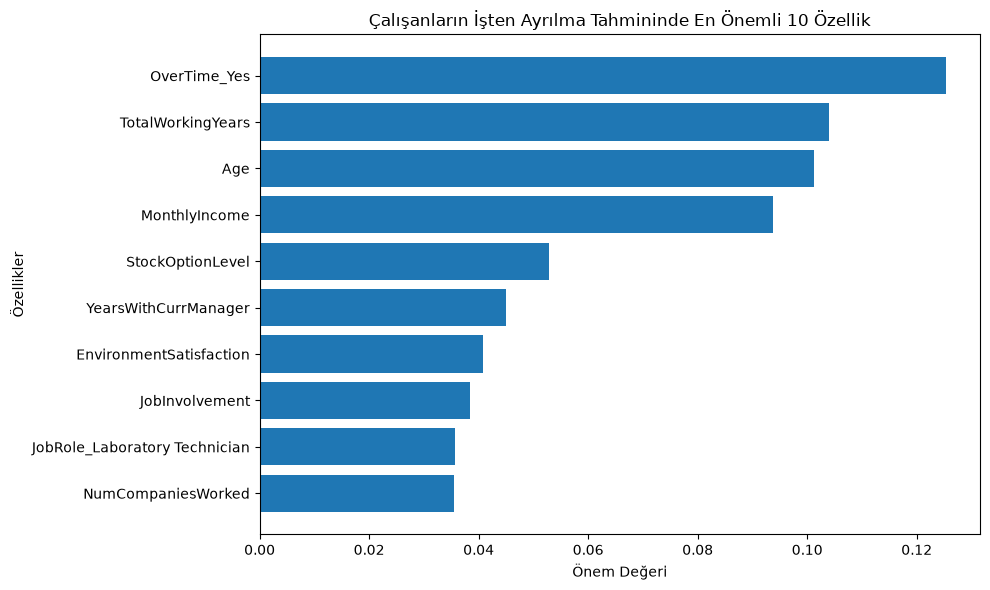

In [46]:
import matplotlib.pyplot as plt

# En önemli 10 özelliği seç
top_10 = importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

# Grafiği oluştur
plt.figure(figsize=(10, 6))
plt.barh(top_10["Feature"], top_10["Importance"])

plt.xlabel("Önem Değeri")
plt.ylabel("Özellikler")
plt.title("Çalışanların İşten Ayrılma Tahmininde En Önemli 10 Özellik")
plt.tight_layout()
plt.show()

Çalışanların İşten Ayrılma Tahmininde En Önemli 10 Özellik

Gradient Boosting modelinin tahminlerinde etkili olan değişkenleri görsel olarak incelemek amacıyla en yüksek önem değerine sahip 10 özellik yatay sütun grafiği ile gösterilmiştir. Grafikte özellikler önem değerlerine göre sıralanmış ve karşılaştırılmıştır.

Grafik sonuçlarına göre OverTime_Yes (fazla mesai durumu) yaklaşık 0,13 önem değeriyle ilk sırada yer almaktadır. Bunu yaklaşık 0,11 ile TotalWorkingYears (toplam çalışma yılı), 0,10 ile Age (yaş) ve 0,09 ile MonthlyIncome (aylık gelir) değişkenleri izlemektedir.

StockOptionLevel (hisse senedi opsiyon düzeyi), YearsWithCurrManager (mevcut yöneticiyle çalışma süresi), EnvironmentSatisfaction (çalışma ortamından memnuniyet) ve JobInvolvement (işe bağlılık) değişkenleri de modelin tahminlerinde önem taşıyan diğer özellikler arasında yer almaktadır. JobRole_Laboratory Technician (laboratuvar teknisyeni pozisyonu) ve NumCompaniesWorked (daha önce çalışılan şirket sayısı) ise ilk 10 özellik arasında bulunmakla birlikte daha düşük önem değerlerine sahiptir.

Bu sonuçlar, modelin çalışanların işten ayrılma durumunu tahmin ederken özellikle fazla mesai, çalışma deneyimi, yaş ve aylık gelir değişkenlerinden yararlandığını göstermektedir. İnsan kaynakları açısından bu değişkenler, çalışan bağlılığı ve iş koşulları üzerine yapılacak daha ayrıntılı incelemeler için yol gösterici olabilir.

In [47]:
person = X_test.iloc[[0]]

prediction = best_model.predict(person)

probability = best_model.predict_proba(person)

if prediction[0] == 1:
    print("Modelin tahmini: Çalışan işten ayrılabilir.")
else:
    print("Modelin tahmini: Çalışan işten ayrılmayabilir.")

print("İşten ayrılma olasılığı:", round(probability[0][1] * 100, 2), "%")
print("İşten ayrılmama olasılığı:", round(probability[0][0] * 100, 2), "%")

Modelin tahmini: Çalışan işten ayrılabilir.
İşten ayrılma olasılığı: 57.7 %
İşten ayrılmama olasılığı: 42.3 %


Test Verisindeki Bir Çalışan İçin Tahmin Sonucunun Raporu
Modelin performansını daha somut bir şekilde değerlendirmek amacıyla test veri setindeki ilk çalışan için tahmin yapılmıştır. Model, çalışanın işten ayrılabileceğini tahmin etmiştir. Tahmin sonucuna göre çalışanın işten ayrılma olasılığı %57,7, işten ayrılmama olasılığı ise %42,3 olarak hesaplanmıştır.

İşten ayrılma olasılığının daha yüksek olması nedeniyle model, bu çalışanı işten ayrılma riski taşıyan bir çalışan olarak sınıflandırmıştır. Bu sonuç, modelin çalışanın kesinlikle işten ayrılacağı anlamına gelmez; yalnızca mevcut veriler ve modelin öğrendiği örüntüler doğrultusunda yapılan bir tahmindir.

Bu örnek, geliştirilen makine öğrenmesi modelinin çalışan bazında tahmin üretmek ve olası işten ayrılma risklerini önceden belirlemeye yardımcı olmak amacıyla kullanılabileceğini göstermektedir. Şirketler bu tür tahminlerden yararlanarak çalışan memnuniyetini artırmaya ve çalışanların işten ayrılma riskini azaltmaya yönelik önlemleri değerlendirebilir.

In [48]:
#Seçilen çalışanın en önemli 10 özelliğindeki değerlerini göster
person_features = person.iloc[0]

for feature in importance_df.head(10)["Feature"]:
    print(f"{feature}: {person_features[feature]}")

OverTime_Yes: 0.0
TotalWorkingYears: 0.025
Age: 0.14285714285714285
MonthlyIncome: 0.05392311743022644
StockOptionLevel: 0.3333333333333333
YearsWithCurrManager: 0.0
EnvironmentSatisfaction: 1.0
JobInvolvement: 0.6666666666666667
JobRole_Laboratory Technician: 0.0
NumCompaniesWorked: 0.1111111111111111


Seçilen Çalışanın En Önemli 10 Özelliğinin İncelenmesi
Modelin işten ayrılma tahmininde önemli bulduğu 10 özelliğin, test veri setinden seçilen ilk çalışan için aldığı değerler incelenmiştir. Sonuçlara göre çalışanın fazla mesai değişkeni (OverTime_Yes) 0, toplam çalışma yılı (TotalWorkingYears) 0,025 ve yaşı (Age) 0,143 olarak görülmektedir. Ayrıca aylık gelir (MonthlyIncome) 0,054, hisse senedi opsiyon seviyesi (StockOptionLevel) 0,333 ve mevcut yöneticisiyle çalışma süresi (YearsWithCurrManager) 0 olarak hesaplanmıştır.

Çalışanın çevre memnuniyeti (EnvironmentSatisfaction) değeri 1, iş katılımı (JobInvolvement) değeri yaklaşık 0,667, Laboratuvar Teknisyeni rolünü belirten değişken (JobRole_Laboratory Technician) 0 ve daha önce çalıştığı şirket sayısı (NumCompaniesWorked) yaklaşık 0,111'dir.

In [49]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [50]:
import shap
import pandas as pd
import matplotlib.pyplot as plt

# Modelin kararlarını açıklamak için SHAP açıklayıcısını oluştur
explainer = shap.TreeExplainer(best_model)

# Seçtiğimiz çalışan için SHAP değerlerini hesapla
shap_values = explainer.shap_values(person)

print("SHAP analizi tamamlandı.")

c:\Users\adelikan\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP analizi tamamlandı.


SHAP Analizi ile Model Kararlarının Açıklanması
Bu kodda, geliştirilen Gradient Boosting modeli için SHAP açıklayıcısı oluşturulmuş ve test veri setinden seçilen ilk çalışan için SHAP değerleri hesaplanmıştır.

SHAP analizi, modelin bir çalışan için neden işten ayrılma veya işte kalma tahmini yaptığını anlamaya yardımcı olur. Özelliklerin tahmine katkısını ayrı ayrı inceleyerek modelin kararlarını daha anlaşılır hâle getirir.

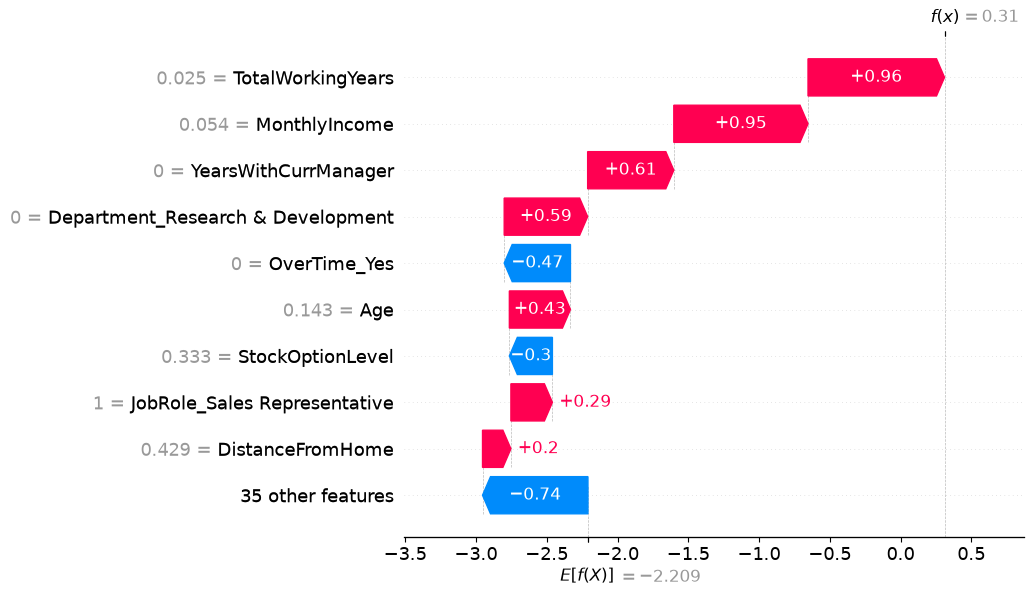

In [51]:
import numpy as np
import shap

# SHAP değerlerini düzenle
sv = shap_values

if isinstance(sv, list):
    sv = sv[1] if len(sv) > 1 else sv[0]

if len(sv.shape) == 3:
    sv = sv[:, :, 1]

# Temel değeri güvenli şekilde al
base = np.asarray(explainer.expected_value).reshape(-1)
base = base[1] if len(base) > 1 else base[0]

# Çalışan için açıklama oluştur
explanation = shap.Explanation(
    values=np.asarray(sv)[0],
    base_values=float(base),
    data=person.iloc[0].values,
    feature_names=person.columns.tolist()
)

# Grafiği göster
shap.plots.waterfall(explanation, max_display=10)

SHAP ile Bireysel Tahminin Açıklanması
Modelin kararlarını daha anlaşılır hâle getirmek amacıyla SHAP (SHapley Additive exPlanations) yöntemi kullanılmıştır. Bu yöntem, bir tahminde her özelliğin model çıktısına katkısını incelemeye yardımcı olur.
Örnek olarak seçilen bir çalışan için model, işten ayrılma olasılığını %57,7, işten ayrılmama olasılığını ise %42,3 olarak hesaplamıştır. SHAP waterfall grafiği, çalışanın özelliklerinin modelin başlangıç tahminini nasıl değiştirdiğini görselleştirmek için oluşturulmuştur.
Grafikte pozitif SHAP değerleri incelenen sınıfın model çıktısını artırırken, negatif SHAP değerleri azaltır. Bu katkılar modelin çıktısı ölçeğinde yorumlanmalıdır; doğrudan nedensellik göstermez.
Bu analiz, çalışanların işten ayrılma tahminlerinin daha şeffaf biçimde incelenmesini ve insan kaynakları kararlarının desteklenmesini amaçlamaktadır.


5.3. İşletmeye yönelik öneriler
Modelimizin sonuçlarına göre en önemli 10 özellik içinde fazla mesai, toplam çalışma yılı, yaş ve aylık gelir öne çıktı. Ayrıca iş ortamından memnuniyet ve işe katılım da önemli özellikler arasında yer aldı.
1. Fazla mesai ve iş yükünü takip etmek
Fazla mesai, modelde en önemli özellik olarak belirlendi. İşletme, fazla mesai sürelerini ve çalışanların iş yükünü düzenli olarak inceleyebilir.
2. Çalışan memnuniyetini artırmak
İş ortamından memnuniyet ve işe katılım gibi özellikler de modelde önemlidir. Düzenli çalışan anketleri ve birebir görüşmelerle sorunlar erkenden belirlenebilir.
3. Ücret ve kariyer olanaklarını değerlendirmek
Aylık gelir ve toplam çalışma yılı modelin öne çıkan özelliklerindendir. İşletme, ücret politikasını, terfi süreçlerini ve kariyer gelişimi fırsatlarını gözden geçirebilir.
4. Tahminleri tek başına karar amacıyla kullanmamak
Modelin işten ayrılma tahmini, kesin bir sonuç değildir. Çalışanlarla ilgili kararlar yalnızca model çıktısına dayandırılmamalı; insan kaynakları değerlendirmeleriyle desteklenmelidir.
Bu öneriler modelin bulgularına dayanan olası iş aksiyonlarıdır; özelliklerin işten ayrılmaya doğrudan neden olduğunu kanıtlamaz.
5.3. İşletme Açısından Yorumlama ve Öneriler
Model sonuçları, çalışanların işten ayrılma riskini değerlendirirken fazla mesai, toplam çalışma yılı, yaş ve aylık gelir gibi özelliklerin önemli olduğunu göstermiştir. İş ortamından memnuniyet ve işe katılım da tahmin sürecinde dikkate değer özellikler arasında yer almıştır.
Bu bulgular doğrultusunda işletmenin fazla mesai ve iş yükü dağılımını takip etmesi, çalışan memnuniyetini düzenli olarak ölçmesi ve ücret ile kariyer gelişimi olanaklarını değerlendirmesi önerilmektedir.
Geliştirilen model, insan kaynakları departmanının olası riskleri erken fark etmesine yardımcı olabilecek bir karar destek aracı olarak değerlendirilebilir. Bununla birlikte, model tahminleri kesin sonuçlar olarak ele alınmamalı ve çalışanlar hakkında alınan kararlarda tek ölçüt olarak kullanılmamalıdır.
6.1. Proje Sınırlılıkları
Bu projede bazı sınırlılıklar bulunmaktadır. İlk olarak, kullanılan veri seti 1.470 çalışan kaydından oluştuğu için farklı sektörleri ve işletmeleri tam olarak temsil etmeyebilir.
İkinci olarak, işten ayrılan çalışanların sayısının ayrılmayan çalışanlara göre daha az olması sınıf dengesizliğine yol açmaktadır. Optimize edilmiş modelin test verisindeki F1 skoru yaklaşık 0,34 ve recall değeri yaklaşık 0,23 olarak ölçülmüştür. Bu sonuçlar, modelin işten ayrılan çalışanları tespit etme konusunda geliştirilmesi gerektiğini göstermektedir.
Ayrıca eğitim ve test performansları arasındaki fark, aşırı öğrenme ihtimaline işaret etmektedir. Son olarak, özellik önem düzeyleri ve SHAP açıklamaları modelin tahminlerini anlamaya yardımcı olsa da değişkenler arasındaki nedensel ilişkileri kanıtlamaz.
Bu nedenlerle model, kesin kararlar veren bir sistemden ziyade insan kaynakları süreçlerini destekleyen deneysel bir tahmin aracı olarak değerlendirilmelidir.
6.2. Gelecek Çalışmalar
Projeye ek bir ay ayrılması durumunda modelin performansını ve güvenilirliğini artırmaya yönelik çalışmalar yapılabilir. İlk olarak, farklı makine öğrenmesi algoritmaları karşılaştırılarak daha başarılı sonuçlar veren modeller araştırılabilir.
İkinci olarak, sınıf dengesizliğinin etkisini azaltmak amacıyla SMOTE gibi yöntemler yalnızca eğitim verisi üzerinde uygulanıp sonuçları karşılaştırılabilir. Hiperparametre optimizasyonu genişletilerek farklı karar eşiklerinin precision, recall ve F1 skorları üzerindeki etkileri de değerlendirilebilir.
Ayrıca farklı işletmelerden ve dönemlerden daha fazla veri elde edilmesi, modelin genellenebilirliğini incelemeye yardımcı olabilir. Son olarak, SHAP analizleri farklı çalışan örneklerine uygulanarak modelin tahminleri daha ayrıntılı biçimde açıklanabilir.
Bu geliştirmeler, çalışanların işten ayrılma riskini belirlemede daha güvenilir ve insan kaynakları süreçlerine daha fazla katkı sağlayabilecek bir karar destek sistemi oluşturulmasına yardımcı olabilir.
